In [41]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(r'Cleaned_dataset.csv',keep_default_na=False)
df

,race,gender,age,admission_type,discharge_disposition,admission_source,time_in_hospital,num_lab_procedures,num_procedures,num_medications,...,number_diagnoses,A1Cresult,metformin,glipizide,pioglitazone,rosiglitazone,insulin,change,diabetesMed,readmitted
0,Caucasian,Female,85,Urgent,Home,Transfer,13,68,2,28,...,8,None,No,Steady,No,No,Steady,Ch,Yes,0
1,Caucasian,Female,95,Elective,Care facility,Transfer,12,33,3,18,...,8,None,No,No,No,Steady,Steady,Ch,Yes,0
2,Caucasian,Male,45,Emergency,Home,Emergency Room,1,51,0,8,...,5,None,No,Steady,No,No,Steady,Ch,Yes,0
3,AfricanAmerican,Female,45,Emergency,Home,Emergency Room,9,47,2,17,...,9,None,No,No,No,No,Steady,No,Yes,1
4,Caucasian,Male,55,Urgent,Home,Referral,3,31,6,16,...,9,None,No,No,No,No,Steady,No,Yes,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69970,Caucasian,Female,75,Emergency,Home,Emergency Room,9,50,2,33,...,9,>7,No,No,No,No,Steady,Ch,Yes,1
69971,Other,Female,45,Emergency,Home,Emergency Room,14,73,6,26,...,9,>8,No,Steady,No,No,Up,Ch,Yes,1
69972,Other,Female,65,Emergency,Home,Emergency Room,2,46,6,17,...,9,None,No,No,No,No,Steady,No,Yes,1
69973,Caucasian,Female,85,Emergency,Home,Emergency Room,5,76,1,22,...,9,None,No,No,No,No,Up,Ch,Yes,0


In [42]:
X = df.drop(columns=['readmitted'])
y = df['readmitted']
print(X.shape, y.shape)

(69975, 25) (69975,)


In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(55980, 25) (13995, 25)
(55980,) (13995,)


In [44]:
from sklearn.preprocessing import LabelEncoder
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])
    X_test[col] = le.transform(X_test[col])
    encoders[col] = le
X_train.head

C:\Users\sidha\AppData\Local\Temp\ipykernel_37700\4293406459.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include='object').columns.tolist()


<bound method NDFrame.head of        race  gender  age  admission_type  discharge_disposition  \
30219     2       0   85               1                      2   
12184     2       0   75               1                      6   
27803     2       1   75               1                      1   
54783     0       0   55               0                      1   
2871      2       0   55               5                      1   
...     ...     ...  ...             ...                    ...   
44597     2       1   35               4                      1   
57752     2       0   55               5                      2   
34307     2       1   55               0                      1   
32076     5       1   75               0                      2   
48604     2       1   55               0                      0   

       admission_source  time_in_hospital  num_lab_procedures  num_procedures  \
30219                 0                 3                  60               0   
121

In [45]:
import joblib
joblib.dump(encoders, 'encoders.pkl')

['encoders.pkl']

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
from xgboost import XGBClassifier
dt.fit(X_train, y_train)

print(classification_report(y_test, dt.predict(X_test)))
print('ROC-AUC:', round(roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1]), 4))

              precision    recall  f1-score   support

           0       0.63      0.86      0.73      8294
           1       0.57      0.28      0.37      5701

    accuracy                           0.62     13995
   macro avg       0.60      0.57      0.55     13995
weighted avg       0.61      0.62      0.58     13995

ROC-AUC: 0.6116


In [47]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=20, random_state=42)
rf.fit(X_train, y_train)

print(classification_report(y_test, rf.predict(X_test)))
print('ROC-AUC:', round(roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]), 4))

              precision    recall  f1-score   support

           0       0.63      0.89      0.74      8294
           1       0.60      0.23      0.33      5701

    accuracy                           0.62     13995
   macro avg       0.61      0.56      0.54     13995
weighted avg       0.62      0.62      0.57     13995

ROC-AUC: 0.6455


In [48]:
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
xgb.fit(X_train, y_train)

print(classification_report(y_test, xgb.predict(X_test)))
print('ROC-AUC:', round(roc_auc_score(y_test, xgb.predict_proba(X_test)[:, 1]), 4))

              precision    recall  f1-score   support

           0       0.64      0.86      0.73      8294
           1       0.59      0.30      0.40      5701

    accuracy                           0.63     13995
   macro avg       0.61      0.58      0.57     13995
weighted avg       0.62      0.63      0.60     13995

ROC-AUC: 0.6508


In [49]:
prob = xgb.predict_proba(X_test)[:, 1]

for t in [0.5, 0.45, 0.4, 0.35, 0.3]:
    pred = (prob >= t).astype(int)
    print('threshold', t)
    print(classification_report(y_test, pred))

threshold 0.5
              precision    recall  f1-score   support

           0       0.64      0.86      0.73      8294
           1       0.59      0.30      0.40      5701

    accuracy                           0.63     13995
   macro avg       0.61      0.58      0.57     13995
weighted avg       0.62      0.63      0.60     13995

threshold 0.45
              precision    recall  f1-score   support

           0       0.67      0.75      0.70      8294
           1       0.55      0.45      0.50      5701

    accuracy                           0.63     13995
   macro avg       0.61      0.60      0.60     13995
weighted avg       0.62      0.63      0.62     13995

threshold 0.4
              precision    recall  f1-score   support

           0       0.69      0.59      0.64      8294
           1       0.51      0.62      0.56      5701

    accuracy                           0.60     13995
   macro avg       0.60      0.61      0.60     13995
weighted avg       0.62      0.

# threshold=4 is best

In [50]:
for d in [X_train, X_test]:
    d['total_visits'] = d['number_outpatient'] + d['number_emergency'] + d['number_inpatient']

xgb3 = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
xgb3.fit(X_train, y_train)
print('ROC-AUC:', round(roc_auc_score(y_test, xgb3.predict_proba(X_test)[:, 1]), 4))
# no use

ROC-AUC: 0.6504


In [51]:
X_train = X_train.drop(columns=['total_visits'])
X_test = X_test.drop(columns=['total_visits'])
print(X_train.shape, X_test.shape)

(55980, 25) (13995, 25)


In [ ]:
# from lightgbm import LGBMClassifier

# lgbm = LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42, verbose=-1)
# lgbm.fit(X_train, y_train)

# print('ROC-AUC:', round(roc_auc_score(y_test, lgbm.predict_proba(X_test)[:, 1]), 4))
#no use

ROC-AUC: 0.6513


<Axes: >

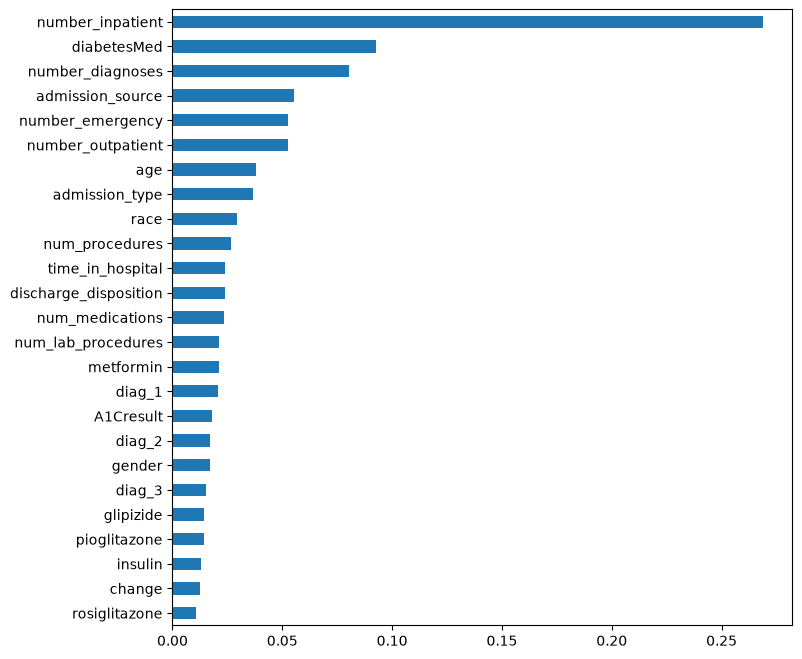

In [56]:
imp = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 8))

In [ ]:
# weak = ['rosiglitazone', 'change', 'insulin', 'pioglitazone', 'glipizide']

# xgb4 = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
# xgb4.fit(X_train.drop(columns=weak), y_train)

# prob4 = xgb4.predict_proba(X_test.drop(columns=weak))[:, 1]
# print('ROC-AUC:', round(roc_auc_score(y_test, prob4), 4))
# no use

ROC-AUC: 0.6497


In [58]:
from sklearn.model_selection import RandomizedSearchCV

params = {
    'n_estimators': [200, 300, 500],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 5, 10]
}

search = RandomizedSearchCV(XGBClassifier(random_state=42), params, n_iter=15,
                            scoring='roc_auc', cv=3, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print(search.best_params_)
print('CV AUC:', round(search.best_score_, 4))
print('Test AUC:', round(roc_auc_score(y_test, search.predict_proba(X_test)[:, 1]), 4))

{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
CV AUC: 0.6602
Test AUC: 0.6534
